# Task 4 — Model Selection

**Saiket Systems | Machine Learning Internship**

Objective: compare suitable binary classifiers for the `Churn` target. Candidate algorithms follow the task brief: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root even if this notebook is opened from its own task folder.
HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, *HERE.parents] if (p / "Dataset").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the Dataset folder. Open this notebook inside Saiket_ML_Internship.")
DATA_PATH = ROOT / "Dataset" / "Telco_Customer_Churn_Dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Dataset path: C:\Users\HP\Desktop\Saiket_ML_Internship\Dataset\Telco_Customer_Churn_Dataset.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Prepare features and create a stratified split

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(r"^\\s*$", np.nan, regex=True), errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
y = df["Churn"].map({"No": 0, "Yes": 1})
X = pd.get_dummies(df.drop(columns=["Churn", "customerID"]), drop_first=True, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (5634, 30) | Test: (1409, 30)


## 2. Train and compare candidate models

The models use the same train/test split. Logistic Regression includes standardization; tree-based models do not require feature scaling.

In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}
rows = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X_test)[:, 1]
    else:
        proba = model.decision_function(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })
results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results.round(4))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Gradient Boosting,0.7984,0.6531,0.5134,0.5749,0.8425
Logistic Regression,0.7388,0.5052,0.7807,0.6134,0.8412
Random Forest,0.7757,0.5671,0.6551,0.6079,0.8275
Decision Tree,0.7381,0.5041,0.8182,0.6239,0.8256


## 3. Select a candidate and inspect performance

Candidate with highest test ROC-AUC: Gradient Boosting
\nClassification report:
              precision    recall  f1-score   support

    No churn       0.84      0.90      0.87      1035
       Churn       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



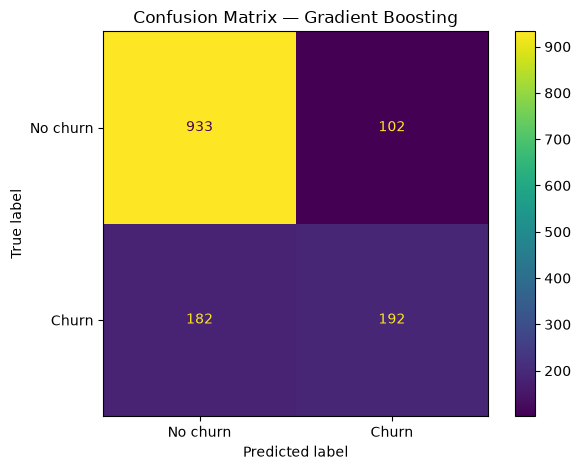

In [4]:
best_name = results.index[0]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)
print("Candidate with highest test ROC-AUC:", best_name)
print("\\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No churn", "Churn"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["No churn", "Churn"])
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()


## 4. Conclusion

Choose the final model by balancing recall, precision, F1-score, ROC-AUC, interpretability, and the business cost of missed churners. ROC-AUC is used here to rank candidates; the highest score on one split is not a guarantee of best real-world performance.

In [5]:
print("Model comparison complete.")
print("Highest ROC-AUC model:", best_name)
print("Remember: the default classification threshold may not be optimal for retention campaigns.")


Model comparison complete.
Highest ROC-AUC model: Gradient Boosting
Remember: the default classification threshold may not be optimal for retention campaigns.
